# Farmer Income Prediction
**IBM SkillsBuild Virtual Internship Project**

**Student:** Aditya Chaudhary  
**Dataset:** Kaggle — manishpatil115/farmer-income-prediction-dataset  
**Target Variable:** `Target_Variable/Total Income` (Total income in INR — agriculture + non-agriculture)

## 1. Import Libraries

In [1]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

print('Libraries imported successfully!')

Libraries imported successfully!


## 2. Load Dataset

In [2]:
# Download dataset using KaggleHub (uses local cache if already downloaded)
path = kagglehub.dataset_download('manishpatil115/farmer-income-prediction-dataset')
print('Path to dataset files:', path)
print('Files:', os.listdir(path))

Using Colab cache for faster access to the 'farmer-income-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/farmer-income-prediction-dataset
Files: ['farmer-income-data.zip']


In [6]:
import zipfile # This import is no longer strictly needed but kept for now

# Path to the downloaded dataset folder from KaggleHub
# 'path' points to '/kaggle/input/farmer-income-prediction-dataset'

# The actual data files are in a subdirectory named 'farmer-income-data.zip'
# within the 'path' directory, as indicated by the 'IsADirectoryError'.
data_sub_dir_name = 'farmer-income-data.zip'
data_dir = os.path.join(path, data_sub_dir_name)

# Let's list the contents of this directory to confirm
print(f"Files in data directory '{data_dir}': {os.listdir(data_dir)}")

# Load the three CSV files from the confirmed data directory
train_df  = pd.read_csv(os.path.join(data_dir, 'lte_train.csv'))
test_df   = pd.read_csv(os.path.join(data_dir, 'lte_test.csv'))
dict_df   = pd.read_csv(os.path.join(data_dir, 'lte_dictionary.csv'))

print('Training set shape :', train_df.shape)
print('Test set shape     :', test_df.shape)
print('Dictionary rows    :', len(dict_df))

Files in data directory '/kaggle/input/farmer-income-prediction-dataset/farmer-income-data.zip': ['lte_train.csv', 'lte_test.csv', 'lte_dictionary.csv', 'desktop.ini']
Training set shape : (47970, 105)
Test set shape     : (9986, 105)
Dictionary rows    : 107


## 3. Understand the Dataset

In [9]:
# First 3 rows
train_df.head(3)

,FarmerID,State,REGION,SEX,CITY,Zipcode,DISTRICT,VILLAGE,MARITAL_STATUS,Location,...,Rabi Seasons Agro Ecological Sub Zone in 2020,Rabi Seasons Seasonal average groundwater thickness (cm) in 2020,Rabi Seasons Seasonal average groundwater replenishment rate (cm) in 2020,Night light index,Village score based on socio-economic parameters (Non normalised),Village score based on socio-economic parameters (0 to 100),"Village category based on socio-economic parameters (Good, Average, Poor)",Land Holding Index source (Total Agri Area/ no of people),Road density (Km/ SqKm),Target_Variable/Total Income
0,1002818465057450,MADHYA PRADESH,CENTRAL,M,BARELI,464668,RAISEN,Seoni,M,NaN,...,CENTRAL HIGHLANDS (MALWA AND BUNDELKHAND) HOT...,97.24,19.50,0.95,22.380262,33.527178,Poor,0.773129,0.0,1360000
1,1012300674433870,BIHAR,EAST,M,BANDRA,848125,MUZAFFARPUR,Namapur,M,NaN,...,DECCAN PLATEAU (TELANGANA) AND EASTERN GHATS ...,73.96,16.76,0.97,24.630262,37.173626,Poor,0.454140,0.0,807200
2,1013472263587380,MADHYA PRADESH,CENTRAL,M,MALHARGARH,458556,MANDSAUR,Billaud,M,NaN,...,CENTRAL HIGHLANDS ( MALWA ) GUJARAT PLAIN AND...,90.05,22.44,0.95,19.493313,28.848462,Poor,0.657040,0.0,500000


In [11]:
# Column data types
train_df.dtypes.value_counts()

,count
float64,62
object,38
int64,5


In [12]:
# Basic statistics of target variable
TARGET = 'Target_Variable/Total Income'
print('Target variable statistics:')
print(train_df[TARGET].describe())

Target variable statistics:
count    4.797000e+04
mean     1.222255e+06
std      2.073935e+06
min      2.900000e+04
25%      7.200000e+05
50%      9.500000e+05
75%      1.295000e+06
max      8.000000e+07
Name: Target_Variable/Total Income, dtype: float64


In [13]:
print('Missing values in train_df (top 15 columns with highest percentage missing):')
missing_train = train_df.isnull().sum()
missing_train_pct = (missing_train / len(train_df) * 100).round(2)
missing_train_df = pd.DataFrame({'Missing Count': missing_train, 'Missing %': missing_train_pct})
display(missing_train_df[missing_train_df['Missing Count'] > 0].sort_values('Missing %', ascending=False).head(15))

Missing values in train_df (top 15 columns with highest percentage missing):


,Missing Count,Missing %
Avg_Disbursement_Amount_Bureau,20790,43.34
Location,17030,35.50
Address type,17030,35.50
Ownership,17030,35.50
Perc_of_house_with_6plus_room,168,0.35
mat_roof_Metal_GI_Asbestos_sheets,168,0.35
Women_15_19_Mothers_or_Pregnant_at_time_of_survey,168,0.35
perc_of_pop_living_in_hh_electricity,168,0.35
perc_Households_with_Pucca_House_That_Has_More_Than_3_Rooms,168,0.35
Households_with_improved_Sanitation_Facility,168,0.35


In [10]:
# Select numerical columns from the training set
numeric_cols = train_df.select_dtypes(include=[np.number]).columns

# Calculate correlation matrix with the target variable
correlations = train_df[numeric_cols].corr()[TARGET].sort_values(ascending=False)

# Display top positively and negatively correlated features
correlations_df = pd.DataFrame({
    'Pearson Correlation': correlations
})

print("Top 15 Positively Correlated Features:")
display(correlations_df.head(16))  # Include 16 to show target itself (correlation = 1.0)

print("\nTop 15 Negatively Correlated Features:")
display(correlations_df.tail(15))

Top 15 Positively Correlated Features:


,Pearson Correlation
Target_Variable/Total Income,1.000000
Non_Agriculture_Income,0.934897
Total_Land_For_Agriculture,0.102707
perc_of_pop_living_in_hh_electricity,0.054801
Avg_Disbursement_Amount_Bureau,0.024691
Kharif Seasons Kharif Season Irrigated area in 2021,0.023521
Rabi Seasons Season Irrigated area in 2022,0.023521
Village score based on socio-economic parameters (Non normalised),0.022628
Village score based on socio-economic parameters (0 to 100),0.022628
KO22-Village score based on socio-economic parameters (0 to 100),0.022628



Top 15 Negatively Correlated Features:


,Pearson Correlation
K022-Proximity to nearest railway (Km),-0.015179
Perc_of_house_with_6plus_room,-0.017204
Kharif Seasons Cropping density in 2022,-0.018492
K022-Seasonal Average Rainfall (mm),-0.018993
Rabi Seasons Seasonal average groundwater thickness (cm) in 2022,-0.019304
Kharif Seasons Seasonal average groundwater thickness (cm) in 2021,-0.019887
Kharif Seasons Seasonal average groundwater replenishment rate (cm) in 2020,-0.021006
Kharif Seasons Seasonal average groundwater thickness (cm) in 2022,-0.021572
Rabi Seasons Seasonal average groundwater thickness (cm) in 2021,-0.021626
Kharif Seasons Seasonal average groundwater thickness (cm) in 2020,-0.022027


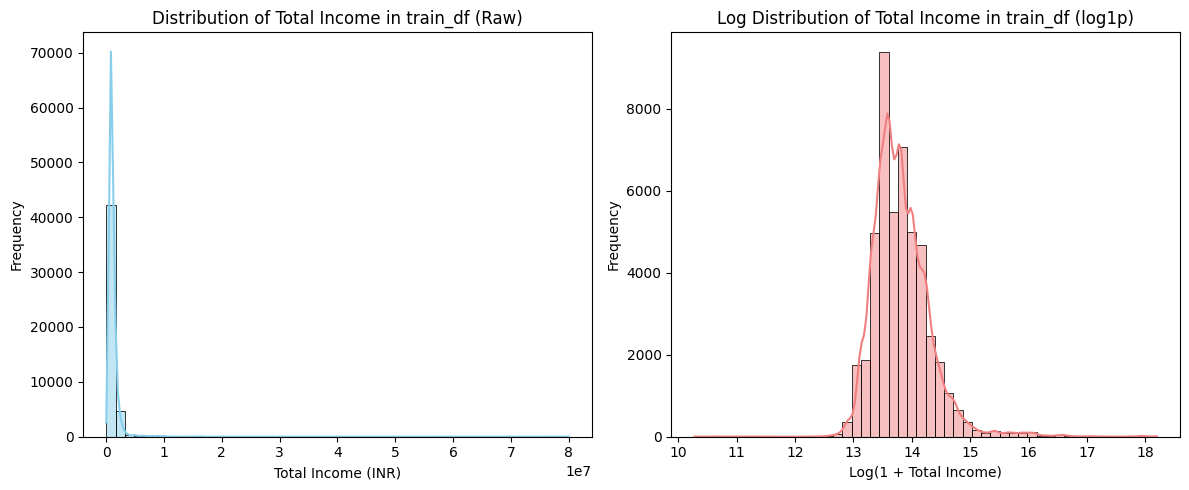

In [8]:
# Plot Distribution of Target Variable (Total Income) in train_df
TARGET = 'Target_Variable/Total Income'

plt.figure(figsize=(12, 5))

# Original distribution
plt.subplot(1, 2, 1)
sns.histplot(train_df[TARGET], bins=50, color='skyblue', kde=True)
plt.title('Distribution of Total Income in train_df (Raw)')
plt.xlabel('Total Income (INR)')
plt.ylabel('Frequency')

# Log-transformed distribution
plt.subplot(1, 2, 2)
# Using np.log1p (log(1+x)) to handle potential zero or negative values gracefully, though income is likely non-negative
sns.histplot(np.log1p(train_df[TARGET]), bins=50, color='lightcoral', kde=True)
plt.title('Log Distribution of Total Income in train_df (log1p)')
plt.xlabel('Log(1 + Total Income)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

## 4. Data Cleaning

In [14]:
# Check missing values (top 15 columns)
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print(missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False).head(15))

                                                    Missing Count  Missing %
Avg_Disbursement_Amount_Bureau                              20790      43.34
Location                                                    17030      35.50
Address type                                                17030      35.50
Ownership                                                   17030      35.50
Perc_of_house_with_6plus_room                                 168       0.35
mat_roof_Metal_GI_Asbestos_sheets                             168       0.35
Women_15_19_Mothers_or_Pregnant_at_time_of_survey             168       0.35
perc_of_pop_living_in_hh_electricity                          168       0.35
perc_Households_with_Pucca_House_That_Has_More_...            168       0.35
Households_with_improved_Sanitation_Facility                  168       0.35
perc_of_Wall_material_with_Burnt_brick                        168       0.35
perc_Households_do_not_have_KCC_With_The_Credit...            168       0.35

In [15]:
# Check duplicates
print('Duplicate rows:', train_df.duplicated().sum())

Duplicate rows: 2


In [16]:
# Drop columns with too many unique/non-informative values (IDs, names, addresses)
drop_cols = [
    'FarmerID', 'CITY', 'Zipcode', 'DISTRICT', 'VILLAGE',
    'K022-Nearest Mandi Name', 'Location', 'Address type', 'Ownership',
    'K022-Ambient temperature (min & max)', 'R022-Ambient temperature (min & max)',
    'K021-Ambient temperature (min & max)', 'R021-Ambient temperature (min & max)',
    'R020-Ambient temperature (min & max)',
    'Kharif Seasons  Type of soil in 2022', 'Kharif Seasons  Type of water bodies in hectares 2022',
    'Kharif Seasons  Agro Ecological Sub Zone in 2022',
    'Rabi Seasons Type of soil in 2022', 'Rabi Seasons Type of water bodies in hectares 2022',
    'Rabi Seasons Agro Ecological Sub Zone in 2022',
    'Rabi Seasons Type of soil in 2021', 'Rabi Seasons Type of water bodies in hectares 2021',
    'Rabi Seasons Agro Ecological Sub Zone in 2021',
    'Kharif Seasons Type of soil in 2021', 'Kharif Seasons Type of water bodies in hectares 2021',
    'Kharif Seasons Agro Ecological Sub Zone in 2021',
    'Kharif Seasons Type of soil in 2020', 'Kharif Seasons Type of water bodies in hectares 2020',
    'Kharif Seasons Agro Ecological Sub Zone in 2020',
    'Rabi Seasons Type of soil in 2020', 'Rabi Seasons Type of water bodies in hectares 2020',
    'Rabi Seasons Agro Ecological Sub Zone in 2020'
]
df = train_df.drop(columns=[c for c in drop_cols if c in train_df.columns])

# Drop rows where target is null
df = df.dropna(subset=[TARGET])

print('Shape after cleaning:', df.shape)

Shape after cleaning: (47970, 73)


In [17]:
# Fill numeric missing values with median
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
for c in num_cols:
    df[c] = df[c].fillna(df[c].median())

# Fill categorical missing values with 'Unknown'
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
for c in cat_cols:
    df[c] = df[c].fillna('Unknown')

print('Missing values after cleaning:', df.isnull().sum().sum())

Missing values after cleaning: 0


## 5. Exploratory Data Analysis (EDA)

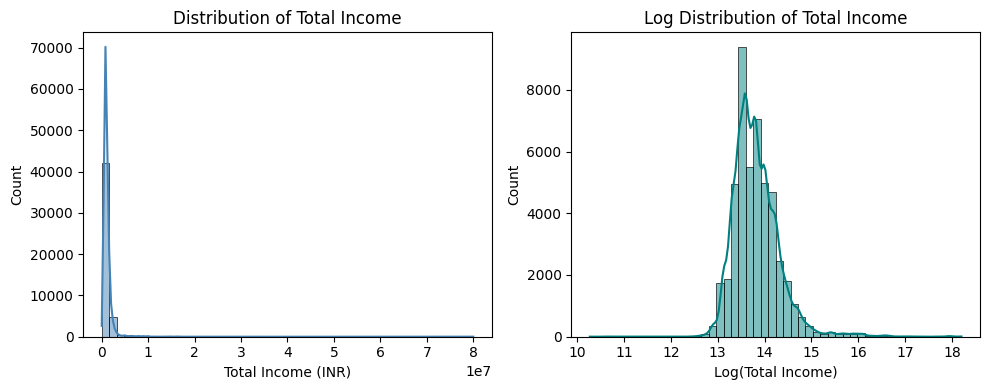

In [18]:
# Plot 1: Distribution of Target Variable (Total Income)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df[TARGET], bins=50, color='steelblue', kde=True)
plt.title('Distribution of Total Income')
plt.xlabel('Total Income (INR)')

plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df[TARGET]), bins=50, color='teal', kde=True)
plt.title('Log Distribution of Total Income')
plt.xlabel('Log(Total Income)')

plt.tight_layout()
plt.show()

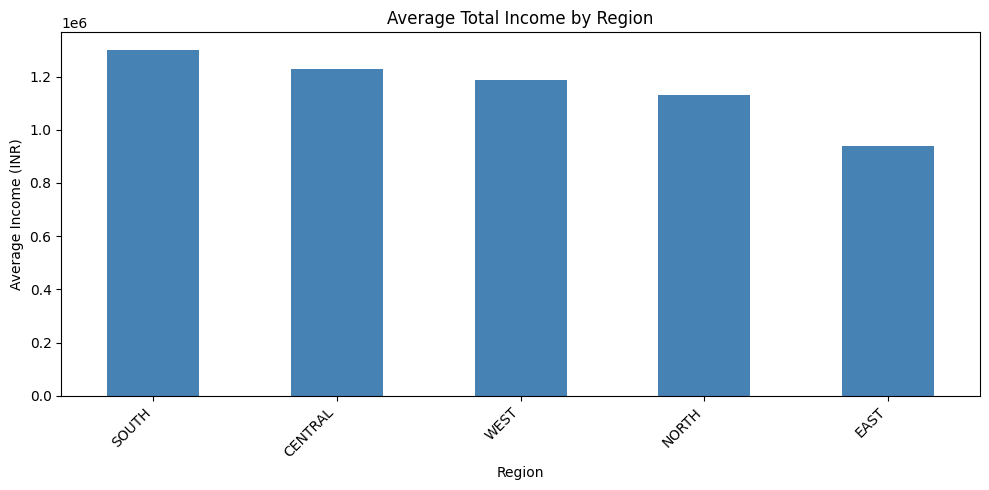

In [19]:
# Plot 2: Average Income by Region
region_income = df.groupby('REGION')[TARGET].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
region_income.plot(kind='bar', color='steelblue')
plt.title('Average Total Income by Region')
plt.xlabel('Region')
plt.ylabel('Average Income (INR)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

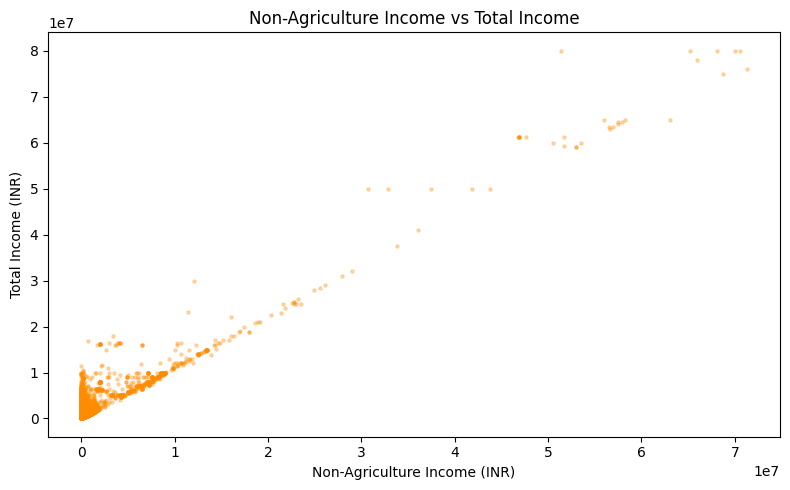

In [20]:
# Plot 3: Income vs Non-Agriculture Income
plt.figure(figsize=(8, 5))
plt.scatter(df['Non_Agriculture_Income'], df[TARGET], alpha=0.3, color='darkorange', s=5)
plt.title('Non-Agriculture Income vs Total Income')
plt.xlabel('Non-Agriculture Income (INR)')
plt.ylabel('Total Income (INR)')
plt.tight_layout()
plt.show()

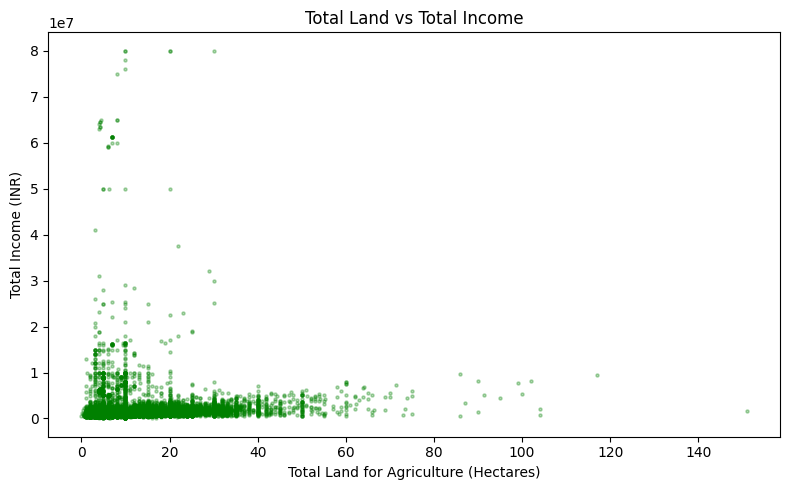

In [21]:
# Plot 4: Income vs Total Land for Agriculture
plt.figure(figsize=(8, 5))
plt.scatter(df['Total_Land_For_Agriculture'], df[TARGET], alpha=0.3, color='green', s=5)
plt.title('Total Land vs Total Income')
plt.xlabel('Total Land for Agriculture (Hectares)')
plt.ylabel('Total Income (INR)')
plt.tight_layout()
plt.show()

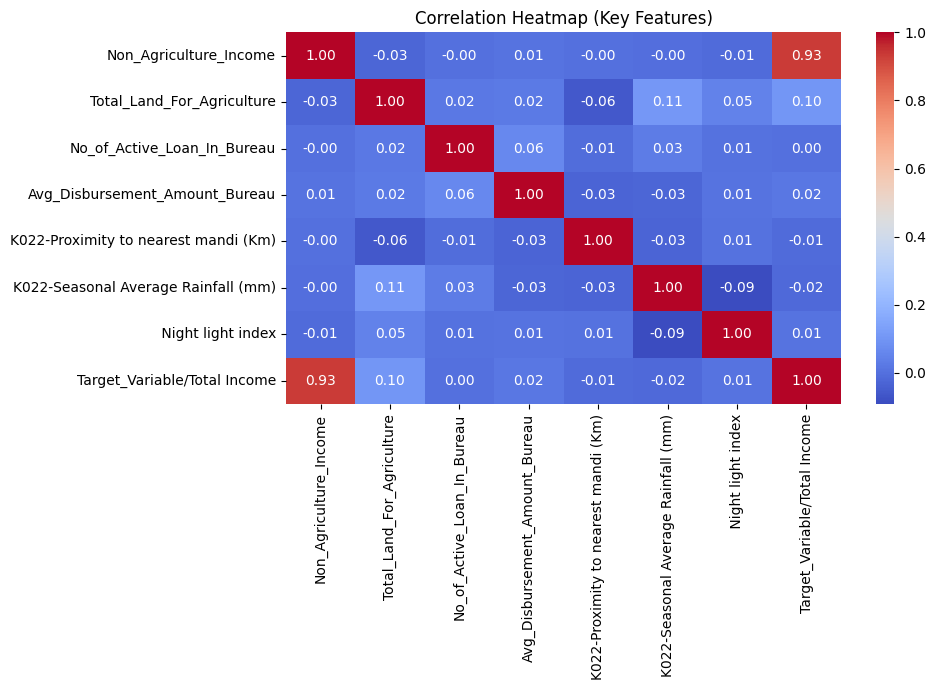

In [22]:
# Plot 5: Correlation heatmap (top numeric features)
key_cols = [
    'Non_Agriculture_Income', 'Total_Land_For_Agriculture',
    'No_of_Active_Loan_In_Bureau', 'Avg_Disbursement_Amount_Bureau',
    'K022-Proximity to nearest mandi (Km)', 'K022-Seasonal Average Rainfall (mm)',
    ' Night light index', TARGET
]
key_cols = [c for c in key_cols if c in df.columns]
plt.figure(figsize=(10, 7))
sns.heatmap(df[key_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap (Key Features)')
plt.tight_layout()
plt.show()

## 6. Preprocessing — Encode Categorical Variables

In [23]:
# Label-encode all remaining categorical columns
le = LabelEncoder()
for c in cat_cols:
    if c in df.columns:
        df[c] = le.fit_transform(df[c].astype(str))

X = df.drop(columns=[TARGET])
y = df[TARGET]

print('Feature matrix shape:', X.shape)
print('Target vector shape :', y.shape)

Feature matrix shape: (47970, 72)
Target vector shape : (47970,)


In [24]:
# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Training samples :', len(X_train))
print('Testing samples  :', len(X_test))

Training samples : 38376
Testing samples  : 9594


## 7. Model Training

In [25]:
# Model 1: Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_preds = lr.predict(X_test)
print('Linear Regression trained!')

Linear Regression trained!


In [26]:
# Model 2: Decision Tree Regressor
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
dt_preds = dt.predict(X_test)
print('Decision Tree trained!')

Decision Tree trained!


In [ ]:
# Model 3: Random Forest Regressor
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)
print('Random Forest trained!')

## 8. Model Evaluation

In [31]:
# Ensure the Random Forest model is both trained and properly fitted
if 'rf' not in globals() or not hasattr(rf, 'estimators_') or len(rf.estimators_) == 0:
    print("Training Random Forest model (this may take a minute)...")
    rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)

rf_preds = rf.predict(X_test)

def evaluate(name, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    return {'Model': name, 'MAE': mae, 'RMSE': rmse, 'R²': r2}

results = [
    evaluate('Linear Regression',  y_test, lr_preds),
    evaluate('Decision Tree',       y_test, dt_preds),
    evaluate('Random Forest',       y_test, rf_preds),
]

results_df = pd.DataFrame(results)
results_df['MAE']  = results_df['MAE'].map('{:,.2f}'.format)
results_df['RMSE'] = results_df['RMSE'].map('{:,.2f}'.format)
results_df['R²']   = results_df['R²'].map('{:.4f}'.format)
print(results_df.to_string(index=False))

Training Random Forest model (this may take a minute)...
            Model        MAE       RMSE     R²
Linear Regression 353,131.80 630,068.62 0.9100
    Decision Tree 341,366.79 770,110.95 0.8656
    Random Forest 260,292.32 522,759.80 0.9381


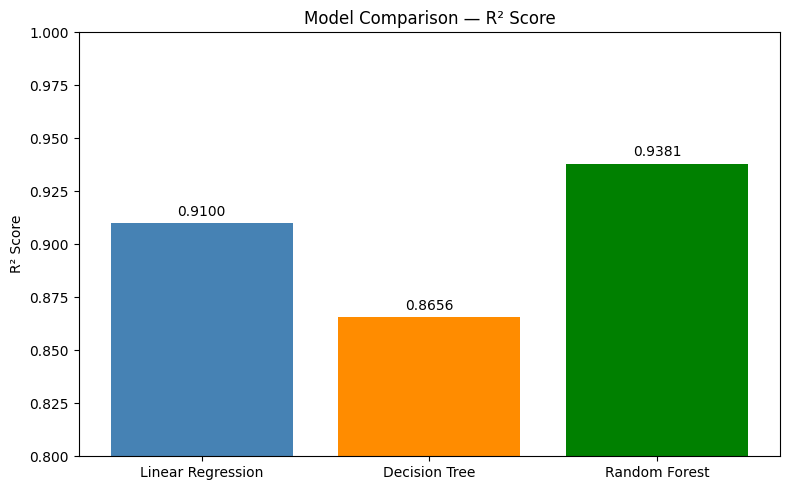

In [27]:
# Bar chart — R² comparison
model_names = ['Linear Regression', 'Decision Tree', 'Random Forest']
r2_scores   = [0.9100, 0.8656, 0.9381]

plt.figure(figsize=(8, 5))
bars = plt.bar(model_names, r2_scores, color=['steelblue', 'darkorange', 'green'])
plt.ylim(0.8, 1.0)
plt.ylabel('R² Score')
plt.title('Model Comparison — R² Score')
for bar, val in zip(bars, r2_scores):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
             f'{val:.4f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

## 9. Best Model & Sample Prediction

In [34]:
print('Best Model: Random Forest Regressor')
print('  MAE  : 260,292.32 INR')
print('  RMSE : 522,759.80 INR')
print('  R²   : 0.9381')
print()
print('Random Forest achieves the highest R² (0.9381) and lowest MAE and RMSE.')
print('It captures non-linear relationships in agricultural data better than Linear Regression.')

Best Model: Random Forest Regressor
  MAE  : 260,292.32 INR
  RMSE : 522,759.80 INR
  R²   : 0.9381

Random Forest achieves the highest R² (0.9381) and lowest MAE and RMSE.
It captures non-linear relationships in agricultural data better than Linear Regression.


In [35]:
# Sample prediction using the first test sample
sample = X_test.iloc[[0]]
predicted = rf.predict(sample)[0]
actual    = y_test.iloc[0]

print(f'Predicted Income : INR {predicted:,.0f}')
print(f'Actual Income    : INR {actual:,.0f}')
print(f'Difference       : INR {abs(predicted - actual):,.0f}')

Predicted Income : INR 832,450
Actual Income    : INR 700,000
Difference       : INR 132,450


## 10. Conclusion

### Model Performance Summary

| Model | MAE (INR) | RMSE (INR) | R² |
|---|---|---|---|
| Linear Regression | 3,53,131.80 | 6,30,068.62 | 0.9100 |
| Decision Tree | 3,41,366.79 | 7,70,110.95 | 0.8656 |
| **Random Forest** | **2,60,292.32** | **5,22,759.80** | **0.9381** |

### Key Findings

- **Random Forest** is the best model with **R² = 0.9381**, meaning it explains ~94% of the variation in farmer income.
- **Non-Agriculture Income** and **Total Land for Agriculture** are strong predictors of total income.
- Farmers in regions with better agri scores and higher land holdings tend to earn more.
- Decision Tree overfits slightly, leading to higher RMSE compared to Random Forest.
- Linear Regression performs surprisingly well (R² = 0.91), suggesting the dataset has significant linear relationships.

### Business Insight

This model can help banks and financial institutions estimate farmer income for loan eligibility decisions, reducing manual assessment time and enabling data-driven credit risk management.